# Project 02 · Search & Learning to Rank from Scratch

**Track:** Machine Learning / Search  
**Research / product question:** Can we rank relevant e-commerce products above distractors for unseen queries?

**Learning outcome:** Manual BM25, NDCG@K, query-group splits, pairwise RankNet-style learning and tuning.

**Workflow:** Data-generating process → raw-data audit → leakage-safe features → from-scratch baseline → model selection / hyperparameter tuning → held-out evaluation → failure analysis.

> **Synthetic-data disclosure:** All records and outcomes are created in this notebook; they do not describe real customers or credit decisions. Ground truth is constructed for teaching. Numerical results are illustrative of this simulator, not estimates of real-world business impact.

**Reproducibility:** Random seeds are fixed. Run cells top-to-bottom. Install packages from the project-level `requirements.txt`. CPU execution is supported; deep-learning examples deliberately use small models.

> **Portfolio standard:** fully reproducible, synthetic educational data · explicit evaluation protocol · plots and failure analysis · no claims of production accuracy.

We split by **query**, not individual query–document pairs. Graded **relevance labels** are simulated ground truth; clicks are logged separately and are position-biased. A hand-built synonym dictionary is used as domain knowledge, not as a target label.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
SEED = 42
rng = np.random.default_rng(SEED)
plt.rcParams.update({'figure.figsize': (8, 4), 'axes.grid': True, 'grid.alpha': 0.2})

## 1. Simulate query–product judgments

Product relevance is known in the simulator, while click labels are biased by position. **We evaluate on explicit relevance**, not biased click labels. Products are intentionally short and ambiguous.

In [2]:
# Generated product relevance is the offline evaluation target; clicks contain position bias.
from collections import Counter
from sklearn.metrics import ndcg_score
from sklearn.linear_model import LogisticRegression
categories={'laptop':['laptop','notebook','computer'], 'headphones':['headphones','headset','earbuds'], 'camera':['camera','photography','dslr'], 'coffee':['coffee','espresso','beans'], 'shoes':['shoes','sneakers','running']}
products=[]
for cat,words in categories.items():
 for i in range(30):
    products.append({'product_id':f'{cat}_{i}','category':cat,'title':f'{rng.choice(words)} {rng.choice(["pro","budget","wireless","premium","lightweight"])} model {i}','quality':rng.uniform(.05,1),'price':rng.uniform(20,450)})
products=pd.DataFrame(products)
queries=[]
for cat,words in categories.items():
 for i in range(42):
    q=f'{rng.choice(words)} {rng.choice(["best","affordable","premium","lightweight","wireless"])}'
    queries.append({'query_id':len(queries),'query':q,'intent':cat})
queries=pd.DataFrame(queries)
rows=[]
for q in queries.itertuples():
 subset=products.sample(25,random_state=int(q.query_id+100)).copy()
 # Inject relevant items to avoid empty-positive ranking groups.
 subextra=products[products.category==q.intent].sample(7,random_state=int(q.query_id+10))
 subset=pd.concat([subset,subextra]).drop_duplicates('product_id')
 for pos,p in enumerate(subset.itertuples(),1):
    rel=int(p.category==q.intent)*(2+int(p.quality>.7))
    # Simulated biased impressions: position can overwhelm relevance in raw clicks.
    click_prob=(.04+.20*(rel>0)+.22*(rel==3))*np.exp(-.055*(pos-1))
    rows.append((q.query_id,q.query,q.intent,p.product_id,p.title,p.quality,p.price,pos,rel,int(rng.random()<click_prob)))
df=pd.DataFrame(rows,columns=['qid','query','intent','product','title','quality','price','logged_position','relevance','click'])
print(df.head().to_string(index=False));print('Rows',len(df),'groups',df.qid.nunique())

 qid       query intent   product                         title  quality      price  logged_position  relevance  click
   0 laptop best laptop   shoes_8          shoes budget model 8 0.987300 328.636901                1          0      0
   0 laptop best laptop laptop_11      computer budget model 11 0.496078 101.472684                2          2      0
   0 laptop best laptop coffee_28    espresso wireless model 28 0.546500 348.487058                3          0      0
   0 laptop best laptop laptop_15 notebook lightweight model 15 0.418104 143.981085                4          2      1
   0 laptop best laptop   shoes_3   running lightweight model 3 0.774406 136.330025                5          0      0
Rows 6466 groups 210


## 2. Implement BM25 manually

BM25 uses term frequency, inverse document frequency and length normalization. The index is built only from the available product catalog; relevance judgments are never used to form lexical features.

In [3]:
# Implement BM25 from the token/document frequency statistics.
import math, re
from sklearn.preprocessing import StandardScaler
def toks(s):return re.findall(r'[a-z0-9]+',s.lower())
corpus=[toks(x) for x in products.title]
D=len(corpus);docfreq=Counter(t for doc in corpus for t in set(doc));avgdl=np.mean([len(x) for x in corpus]);tf=[Counter(x) for x in corpus]
idx={p:i for i,p in enumerate(products.product_id)}
def bm25(q,product_id,k1=1.5,b=.75):
 j=idx[product_id];dl=len(corpus[j]);score=0.
 for term in toks(q):
    nterm=docfreq[term];idf=np.log(1+(D-nterm+.5)/(nterm+.5))
    freq=tf[j][term];score+=idf*freq*(k1+1)/(freq+k1*(1-b+b*dl/avgdl))
 return score
# Feature construction: no future clicks, logged rank, or relevance is included.
# A domain glossary bridges synonymous e-commerce terms (e.g., computer/laptop).
# This is allowed at inference and never reads relevance or click labels.
canonical={word:cat for cat,words in categories.items() for word in words}
def normalize_tokens(text):
 return [canonical.get(t,t) for t in toks(text)]
normalized_docs=[normalize_tokens(t) for t in products.title]
normalized_tf=[Counter(doc) for doc in normalized_docs]
normalized_df=Counter(t for doc in normalized_docs for t in set(doc))
normalized_avgdl=np.mean([len(doc) for doc in normalized_docs])
def normalized_bm25(query,product_id,k1=1.5,b=.75):
 j=idx[product_id]
 length=len(normalized_docs[j]);score=0.
 for term in normalize_tokens(query):
  term_freq=normalized_tf[j][term]
  freq=normalized_df[term]
  idf=np.log(1+(D-freq+.5)/(freq+.5))
  score+=idf*term_freq*(k1+1)/(term_freq+k1*(1-b+b*length/normalized_avgdl))
 return score
df['bm25']=[bm25(q,p) for q,p in zip(df['query'],df['product'])]
df['normalized_bm25']=[normalized_bm25(q,p) for q,p in zip(df['query'],df['product'])]
df['word_overlap']=[len(set(toks(q))&set(toks(t))) for q,t in zip(df['query'],df['title'])]
features=['bm25','normalized_bm25','word_overlap','quality','price']
print(df[features+['relevance','click']].corr().round(2).to_string())

                 bm25  normalized_bm25  word_overlap  quality  price  relevance  click
bm25             1.00             0.65          0.96    -0.03   0.01       0.41   0.09
normalized_bm25  0.65             1.00          0.70    -0.03  -0.01       0.80   0.17
word_overlap     0.96             0.70          1.00    -0.03   0.01       0.34   0.08
quality         -0.03            -0.03         -0.03     1.00  -0.01       0.11   0.03
price            0.01            -0.01          0.01    -0.01   1.00      -0.03  -0.03
relevance        0.41             0.80          0.34     0.11  -0.03       1.00   0.22
click            0.09             0.17          0.08     0.03  -0.03       0.22   1.00


## 3. Query-safe train, validation and test split

Never split individual rows of the same query across train and test: that inflates offline ranking metrics. All query groups are held out as units.

In [4]:
# Split by query so test queries never appear in model fitting.
qids=np.array(sorted(df.qid.unique()));trq,rest=train_test_split(qids,test_size=.35,random_state=42);vaq,teq=train_test_split(rest,test_size=.5,random_state=42)
sets={'train':df[df.qid.isin(trq)].copy(),'valid':df[df.qid.isin(vaq)].copy(),'test':df[df.qid.isin(teq)].copy()}
print({x:(len(v),v.qid.nunique()) for x,v in sets.items()})
def mean_ndcg(frame,score_col,k=10):
 return np.mean([ndcg_score([g.relevance.to_numpy()],[g[score_col].to_numpy()],k=k) for _,g in frame.groupby('qid')])
print('Validation BM25 NDCG@10:',round(mean_ndcg(sets['valid'],'bm25'),3))

{'train': (4191, 136), 'valid': (1137, 37), 'test': (1138, 37)}
Validation BM25 NDCG@10: 0.616


## 4. Implement pairwise ranking learning

For each query, take pairs with different relevance labels. The difference in document features is classified as a preference using Logistic Regression (RankNet-style pairwise logistic surrogate). We sample balanced forward/reverse pairs.

In [5]:
# Form within-query relevant-versus-irrelevant pairs and fit a ranking loss.
def make_pairs(frame,seed=7,cap=40):
 r=np.random.default_rng(seed);xx=[];yy=[]
 for _,g in frame.groupby('qid'):
    good=g[g.relevance>=2];bad=g[g.relevance==0]
    for _ in range(min(cap,len(good)*len(bad))):
      a=good.iloc[int(r.integers(len(good)))][features].to_numpy(dtype=float)
      b=bad.iloc[int(r.integers(len(bad)))][features].to_numpy(dtype=float)
      xx.extend([a-b,b-a]);yy.extend([1,0])
 return np.array(xx),np.array(yy)
scaler=StandardScaler().fit(sets['train'][features]);
xpair,ypair=make_pairs(sets['train']);scale=scaler.scale_.copy();scale[scale==0]=1
# Scaling differences is equivalent to standardizing each document before subtraction.
xpair=xpair/scale
scores=[];rankers={}
for C in [.03,.3,3.0]:
    model=LogisticRegression(C=C,fit_intercept=False,max_iter=300).fit(xpair,ypair)
    val=sets['valid'].copy();val['rank_score']=model.decision_function(scaler.transform(val[features]))
    metric=mean_ndcg(val,'rank_score');scores.append((C,metric));rankers[C]=model
bestC=max(scores,key=lambda x:x[1])[0]
print('Validation grid:',[(c,round(s,3)) for c,s in scores],'best C',bestC)

Validation grid: [(0.03, np.float64(0.941)), (0.3, np.float64(0.924)), (3.0, np.float64(0.892))] best C 0.03


## 5. Final ranking evaluation and error analysis

We compare random, lexical retrieval, and a reranker using the **untouched test query groups**. A strong reranker can incorporate product quality even when BM25 keyword overlap is imperfect.

Test NDCG@10: {'Random': np.float64(0.347), 'Raw BM25': np.float64(0.604), 'Synonym BM25': np.float64(0.811), 'Pairwise ranker': np.float64(0.934)}


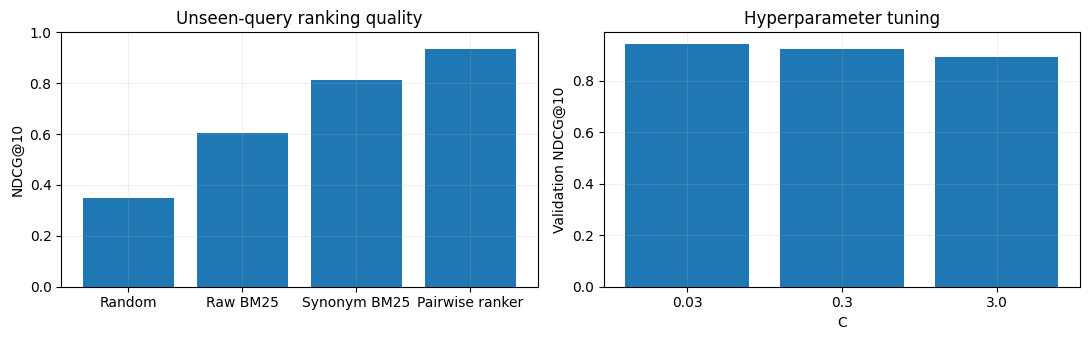

Top-ranked products (one held-out query):
         query                      title  relevance  bm25  rank_score
computer best notebook wireless model 27          3   0.0    3.357017
computer best    notebook budget model 5          2   0.0    3.356479
computer best   laptop wireless model 22          2   0.0    3.339255
computer best notebook wireless model 19          2   0.0    3.301578
computer best  notebook premium model 18          3   0.0    3.280465
computer best    laptop premium model 16          2   0.0    3.280176
A domain glossary is a manually provided synonym feature, not a label lookup.


In [6]:
# Compare selected ranker to random and lexical retrieval on untouched queries.
test=sets['test'].copy();test['random_score']=np.random.default_rng(101).random(len(test));test['rank_score']=rankers[bestC].decision_function(scaler.transform(test[features]))
metrics={n:mean_ndcg(test,c) for n,c in [('Random','random_score'),('Raw BM25','bm25'),('Synonym BM25','normalized_bm25'),('Pairwise ranker','rank_score')]}
print('Test NDCG@10:',{k:round(v,3) for k,v in metrics.items()})
fig,ax=plt.subplots(1,2,figsize=(11,3.5));ax[0].bar(list(metrics),list(metrics.values()));ax[0].set(ylabel='NDCG@10',ylim=(0,1),title='Unseen-query ranking quality');ax[1].bar([str(c) for c,_ in scores],[s for _,s in scores]);ax[1].set(xlabel='C',ylabel='Validation NDCG@10',title='Hyperparameter tuning');plt.tight_layout();plt.show()
example=test[test.qid==test.qid.iloc[0]].sort_values('rank_score',ascending=False)[['query','title','relevance','bm25','rank_score']].head(6)
print('Top-ranked products (one held-out query):\n',example.to_string(index=False))
print('A domain glossary is a manually provided synonym feature, not a label lookup.')

## What the results mean / interview discussion

The split, loss, and metric operate at **query level**, not arbitrary rows. This pairwise scorer is a *reranker over a fixed candidate set*; large-scale retrieval would require an inverted index or vector index and a candidate recall evaluation. Click feedback contains position bias and must not be used as unconfounded relevance.

**Try explaining these without looking at the code:**

1. Why does GroupKFold matter for ranking?
2. What is the difference between candidate recall and NDCG@10?
3. How would you correct position bias in real click logs?

**Limitations and next step:** Evaluate on a suitably licensed real-world dataset or stronger simulation with domain shift, logging bias and realistic selection. Never treat synthetic performance as production evidence.

## What this project demonstrates, and what it does not

**Next:** compare LambdaMART, add explicit click propensity estimation, evaluate rare/unseen intents and measure retrieval latency. A ranking model can lose to a good lexical baseline—never assume complexity guarantees improvement.

**Reproduce:** `Run All` in Jupyter; no private or uploaded data required. For real data, use leakage-safe train/validation/test partitions and respect each dataset license.

### Search failure analysis

Look at a held-out query where the raw BM25 score is zero for a semantically relevant document (e.g., *computer* versus *notebook*). Synonym-normalized retrieval can repair this lexical mismatch. A learned pairwise ranker **may** still underperform a strong lexical baseline on a small synthetic dataset; that is a result, not a test failure.